# ACP do conjunto Wine (UCI)

**Pergunta:** que diferenças na composição química uma ACP permite identificar entre os 178 vinhos? Os três cultivares se distinguem no espaço dos componentes?

**Roteiro**
1. Dados e análise exploratória
2. Padronização (e por que ela é necessária)
3. Autodecomposição da matriz de correlação
4. Quantos componentes reter
5. Interpretação dos componentes
6. Os cultivares no espaço dos componentes
7. Conclusão

## 1. Dados e análise exploratória

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

wine = load_wine(as_frame=True)
X = wine.data          # 13 medidas químicas
y = wine.target        # cultivar (0, 1, 2) -- NÃO entra na ACP
nomes_cultivar = ["Cultivar 0", "Cultivar 1", "Cultivar 2"]

print("Dimensão de X:", X.shape)
print("Valores faltantes:", int(X.isna().sum().sum()))
print("Vinhos por cultivar:", y.value_counts().sort_index().to_dict())

Dimensão de X: (178, 13)
Valores faltantes: 0
Vinhos por cultivar: {0: 59, 1: 71, 2: 48}


In [3]:
X.describe().loc[["mean", "std", "min", "max"]].T.round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Observações.** Não há valores faltantes, os dados são todos numéricos e os três cultivares têm tamanhos parecidos (59, 71 e 48 vinhos), então nenhum grupo domina a análise.

O ponto mais importante é a **diferença de escala** entre as variáveis: a prolina tem média ≈ 747 e desvio ≈ 315, enquanto o teor de cinzas (`ash`) tem média ≈ 2,4 e desvio ≈ 0,27. Isso afeta diretamente a escolha entre ACP sobre a matriz de covariância ou sobre a de correlação, discutida a seguir.

## 2. Padronização: por que usar a matriz de correlação

In [4]:
# ACP SEM padronizar (matriz de covariância), só para mostrar o problema
Xc = X - X.mean()
aut_cov = np.sort(np.linalg.eigvalsh(Xc.cov()))[::-1]
print("Variância explicada pelo CP1 sem padronizar: %.1f%%" % (100 * aut_cov[0] / aut_cov.sum()))

print("\nVariâncias das variáveis originais (maiores):")
print(X.var().sort_values(ascending=False).head(3).round(1).to_string())

Variância explicada pelo CP1 sem padronizar: 99.8%

Variâncias das variáveis originais (maiores):
proline              99166.7
magnesium              204.0
alcalinity_of_ash       11.2


**Decisão: padronizar as variáveis (ACP sobre a matriz de correlação R).**

Sem padronizar, o CP1 explicaria cerca de 99,8% da variância. Isso não revela estrutura química nenhuma: é apenas a prolina, que tem variância ≈ 99.000 (contra ≈ 11 para `alcalinity_of_ash`), "engolindo" as demais variáveis. As unidades das medidas também são diferentes (mg/L, absorbância, razões etc.), então somar suas variâncias brutas não tem sentido.

Padronizar (média 0 e variância 1) dá o mesmo peso a todas as variáveis e equivale a fazer a ACP sobre a matriz de correlação. Os componentes passam a refletir a **estrutura de correlação** entre as medidas, que é o que interessa para a pergunta.

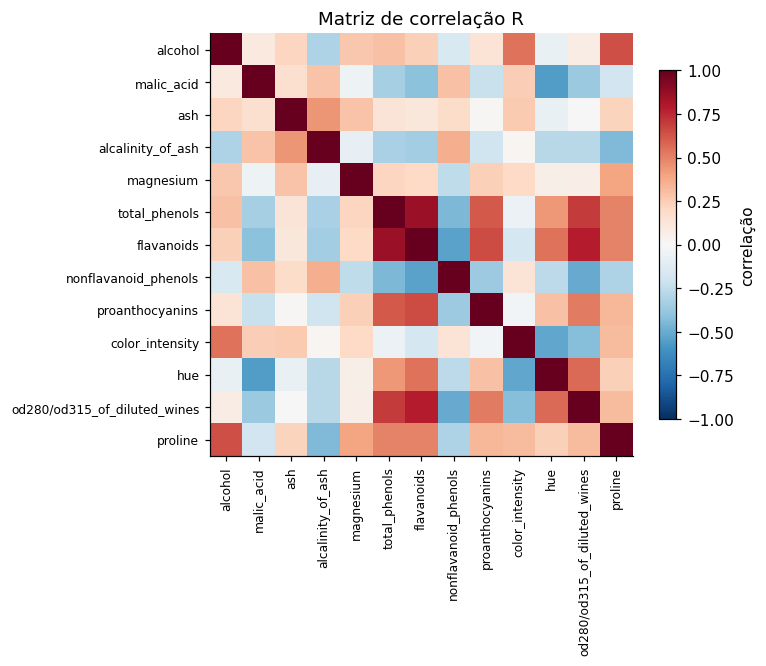

In [5]:
Z = (X - X.mean()) / X.std()      # padronização (ddof=1)
R = Z.corr()                      # como Z já é padronizado, Z.cov() == R

import matplotlib.colors as mcolors
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(13)); ax.set_xticklabels(R.columns, rotation=90, fontsize=8)
ax.set_yticks(range(13)); ax.set_yticklabels(R.columns, fontsize=8)
fig.colorbar(im, shrink=0.8, label="correlação")
ax.set_title("Matriz de correlação R")
plt.tight_layout(); plt.show()

Há blocos de variáveis claramente correlacionadas (por exemplo, `flavanoids`, `total_phenols` e `od280/od315_of_diluted_wines`, todas positivamente associadas, e `nonflavanoid_phenols` correlacionada negativamente com elas). Isso indica que existe redundância, e que a ACP deve conseguir resumir boa parte da informação em poucos componentes.

## 3. Autodecomposição de R

In [6]:
autovalores, E = np.linalg.eigh(R)

# eigh devolve em ordem crescente: invertemos
ordem = autovalores.argsort()[::-1]
autovalores = autovalores[ordem]
E = E[:, ordem]

# O sinal de um autovetor é arbitrário. Fixamos para facilitar a leitura:
#   CP1: flavonoides com carga positiva (CP1 alto = mais fenóis)
#   CP2: intensidade de cor com carga positiva (CP2 alto = vinho mais "intenso")
#   CP3: cinzas (ash) com carga positiva
idx = {v: i for i, v in enumerate(Z.columns)}
for j, var in enumerate(["flavanoids", "color_intensity", "ash"]):
    if E[idx[var], j] < 0:
        E[:, j] *= -1

T = Z.to_numpy() @ E              # escores (178 x 13)

proporcoes = autovalores / autovalores.sum()
acumuladas = np.cumsum(proporcoes)

tabela_CPs = pd.DataFrame({
    "Autovalor": autovalores,
    "Proporção (%)": 100 * proporcoes,
    "Acumulada (%)": 100 * acumuladas,
}, index=[f"CP{i+1}" for i in range(13)]).round(2)
tabela_CPs

,Autovalor,Proporção (%),Acumulada (%)
CP1,4.71,36.20,36.20
CP2,2.50,19.21,55.41
CP3,1.45,11.12,66.53
CP4,0.92,7.07,73.60
CP5,0.85,6.56,80.16
CP6,0.64,4.94,85.10
CP7,0.55,4.24,89.34
CP8,0.35,2.68,92.02
CP9,0.29,2.22,94.24
CP10,0.25,1.93,96.17


## 4. Quantos componentes reter?

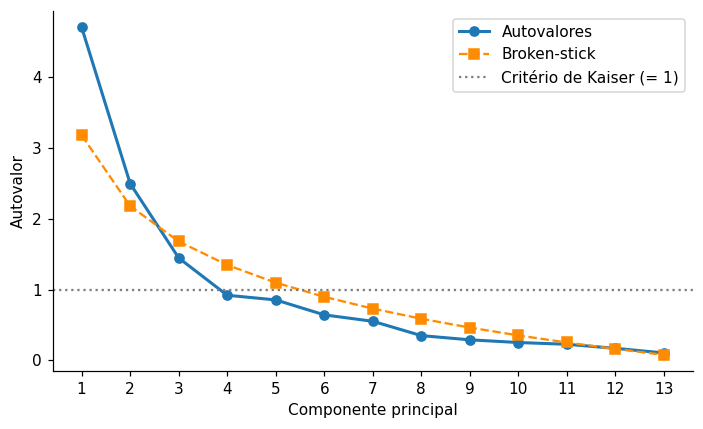

Kaiser (autovalor > 1): 3 componentes
Broken-stick (CP1, CP2, ... enquanto autovalor > esperado): 2 componentes
  CP3: autovalor 1.45 vs esperado 1.68
Variância acumulada CP1-CP2: 55.4% | CP1-CP3: 66.5%


In [7]:
p = len(autovalores)
# Broken-stick: autovalor "esperado" se a variância total fosse repartida ao acaso
broken_stick = np.array([sum(1 / k for k in range(i, p + 1)) for i in range(1, p + 1)])

comp = np.arange(1, p + 1)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(comp, autovalores, "o-", lw=2, label="Autovalores")
ax.plot(comp, broken_stick, "s--", color="darkorange", label="Broken-stick")
ax.axhline(1, color="gray", ls=":", label="Critério de Kaiser (= 1)")
ax.set(xlabel="Componente principal", ylabel="Autovalor", xticks=comp)
ax.legend(); plt.tight_layout(); plt.show()

print("Kaiser (autovalor > 1):", int((autovalores > 1).sum()), "componentes")
# Broken-stick: retém-se os componentes consecutivos, a partir do CP1, enquanto autovalor > esperado
n_bs = int(np.argmin(autovalores > broken_stick)) if not (autovalores > broken_stick).all() else p
print("Broken-stick (CP1, CP2, ... enquanto autovalor > esperado):", n_bs, "componentes")
print("  CP3: autovalor %.2f vs esperado %.2f" % (autovalores[2], broken_stick[2]))
print("Variância acumulada CP1-CP2: %.1f%% | CP1-CP3: %.1f%%" % (100 * acumuladas[1], 100 * acumuladas[2]))

**Decisão.** Os critérios não concordam totalmente:

| Critério | Componentes retidos |
|---|---|
| Cotovelo (scree plot) | 2 (a queda se suaviza a partir do CP3) |
| Broken-stick | 2 (o CP3 tem 1,45 e o esperado ao acaso é 1,68) |
| Kaiser (autovalor > 1) | 3 |

Vamos **reter 2 componentes** (55,4% da variância) como base para a visualização e a interpretação principal, pois dois critérios concordam e permitem um gráfico bidimensional. O CP3 (11,1%) é um caso limítrofe: o Kaiser o aceita e o broken-stick não. Vamos examiná-lo na interpretação e testar, mais adiante, se ele ajuda a separar os cultivares.

Vale reconhecer que 55% é uma variância explicada modesta: os dois primeiros componentes não resumem tudo, e isso será relevante na conclusão.

## 5. Interpretação dos componentes

In [14]:
# Correlação entre cada variável original e cada componente: carga * sqrt(autovalor)
corr_vc = E[:, :3] * np.sqrt(autovalores[:3])
cargas = pd.DataFrame(corr_vc, index=Z.columns, columns=["CP1", "CP2", "CP3"]).round(2)

def destaca(v):
    return "font-weight: bold; background-color: #123D29" if abs(v) >= 0.6 else ""

cargas.style.map(destaca).format("{:.2f}")

,CP1,CP2,CP3
alcohol,0.31,0.76,-0.25
malic_acid,-0.53,0.36,0.11
ash,-0.00,0.50,0.75
alcalinity_of_ash,-0.52,-0.02,0.74
magnesium,0.31,0.47,0.16
total_phenols,0.86,0.10,0.18
flavanoids,0.92,-0.01,0.18
nonflavanoid_phenols,-0.65,0.05,0.20
proanthocyanins,0.68,0.06,0.18
color_intensity,-0.19,0.84,-0.17


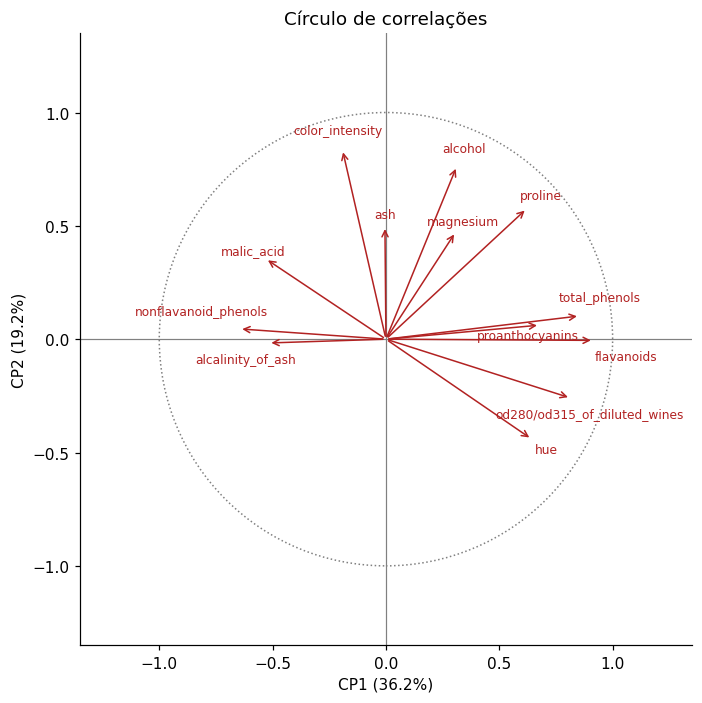

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
# pequenos deslocamentos (dx, dy) para rótulos que se sobrepõem
ajuste = {"total_phenols": (0.0, 0.07), "proanthocyanins": (-0.12, -0.05),
          "flavanoids": (0.05, -0.07), "nonflavanoid_phenols": (-0.1, 0.07),
          "alcalinity_of_ash": (-0.05, -0.07), "od280/od315_of_diluted_wines": (0.0, -0.04)}

for nome, (x, yy) in zip(Z.columns, corr_vc[:, :2]):
    ax.annotate("", xy=(x, yy), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": "firebrick"})
    dx, dy = ajuste.get(nome, (0, 0))
    ax.text(1.1 * x + dx, 1.1 * yy + dy, nome, color="firebrick", fontsize=8, ha="center", va="center")

ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="gray", ls=":"))
ax.axhline(0, color="gray", lw=.8); ax.axvline(0, color="gray", lw=.8)
ax.set(xlabel=f"CP1 ({proporcoes[0]:.1%})", ylabel=f"CP2 ({proporcoes[1]:.1%})",
       xlim=(-1.35, 1.35), ylim=(-1.35, 1.35), title="Círculo de correlações")
ax.set_aspect("equal"); plt.tight_layout(); plt.show()

(Destacadas na tabela, as correlações com |r| ≥ 0,6.)

**CP1 (36,2%): conteúdo fenólico.** Correlaciona-se positivamente com `flavanoids` (0,92), `total_phenols` (0,86), `od280/od315_of_diluted_wines` (0,82), `proanthocyanins` (0,68), `hue` (0,64) e `proline` (0,62), e negativamente com `nonflavanoid_phenols` (−0,65) e `malic_acid` (−0,53). Vinhos com CP1 alto são ricos em fenóis totais e flavonoides, com matiz (hue) mais alto, e têm pouco ácido málico e poucos fenóis não flavonoides.

**CP2 (19,2%): intensidade/concentração.** Opõe-se principalmente `color_intensity` (0,84), `alcohol` (0,76) e `proline` (0,58), e em menor grau `magnesium` (0,47) e `ash` (0,50), à `hue` (−0,44). Vinhos com CP2 alto são mais coloridos, mais alcoólicos e com mais prolina.

**CP3 (11,1%): cinzas e alcalinidade.** `ash` (0,75) e `alcalinity_of_ash` (0,74) dominam. É um eixo mais "específico", de apenas duas variáveis, e já está no limite dos critérios de retenção.

No círculo de correlações, o grupo de fenóis (`flavanoids`, `total_phenols`, `od280/od315`) aponta para o mesmo lado e opõe-se a `nonflavanoid_phenols` e `malic_acid`; já `color_intensity` e `alcohol` apontam quase na direção do CP2. Setas longas, próximas ao círculo unitário, são bem representadas no plano CP1×CP2; setas curtas (`ash`, `alcalinity_of_ash`) são mal representadas nele.

## 6. Os cultivares no espaço dos componentes

A ACP **não usa os rótulos** dos cultivares: eles entram só agora, para colorir os escores. Assim, se os grupos aparecerem separados, é porque as diferenças entre cultivares estão nas direções de maior variância dos dados, e não porque a técnica foi "treinada" para isso.

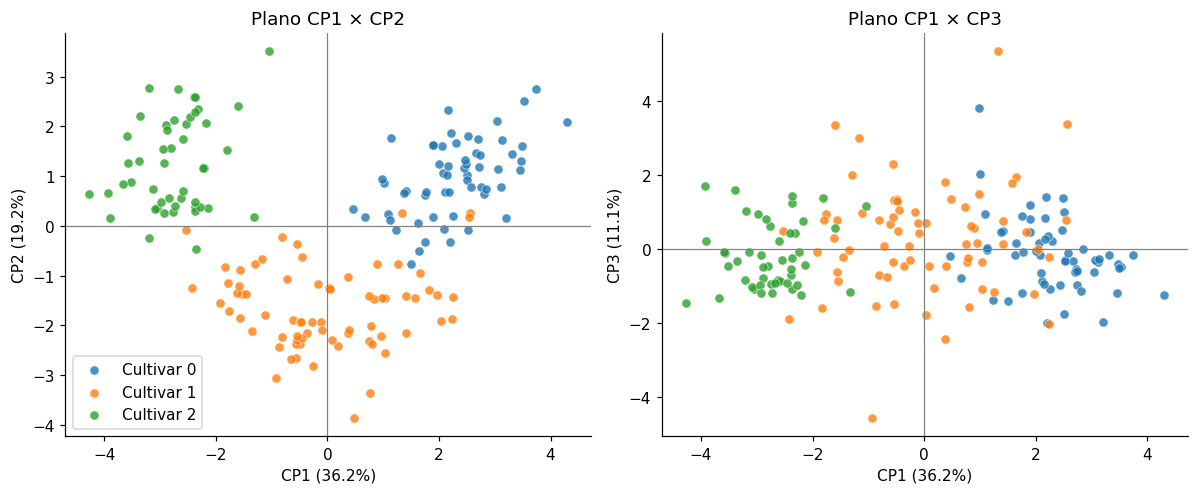

In [10]:
cores = ["tab:blue", "tab:orange", "tab:green"]
pares = [(0, 1), (0, 2)]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (a, b) in zip(axs, pares):
    for k in range(3):
        m = (y == k).to_numpy()
        ax.scatter(T[m, a], T[m, b], c=cores[k], label=nomes_cultivar[k], alpha=.8, edgecolor="white", lw=.4)
    ax.axhline(0, color="gray", lw=.8); ax.axvline(0, color="gray", lw=.8)
    ax.set(xlabel=f"CP{a+1} ({proporcoes[a]:.1%})", ylabel=f"CP{b+1} ({proporcoes[b]:.1%})")
axs[0].set_title("Plano CP1 × CP2"); axs[1].set_title("Plano CP1 × CP3")
axs[0].legend(); plt.tight_layout(); plt.show()

No plano **CP1 × CP2** os três cultivares formam nuvens bem distintas, com pouca sobreposição. No plano **CP1 × CP3**, os grupos ficam sobrepostos na vertical (o CP3 não os distingue). Vamos quantificar essa impressão.

In [11]:
from scipy.stats import f_oneway

df = pd.DataFrame(T[:, :3], columns=["CP1", "CP2", "CP3"])
df["Cultivar"] = y.map(dict(enumerate(nomes_cultivar))).to_numpy()

medias = df.groupby("Cultivar").agg(["mean", "std"]).round(2)
display(medias)

anova = pd.DataFrame({
    c: dict(zip(["F", "p-valor"], f_oneway(*[df.loc[df.Cultivar == g, c] for g in nomes_cultivar])))
    for c in ["CP1", "CP2", "CP3"]
}).T
anova["F"] = anova["F"].round(1)
anova["p-valor"] = anova["p-valor"].map("{:.1e}".format)
anova

CP1         CP2         CP3      
            mean   std  mean   std  mean   std
Cultivar                                      
Cultivar 0  2.28  0.80  0.97  0.77 -0.16  0.99
Cultivar 1 -0.04  1.25 -1.64  0.82  0.26  1.48
Cultivar 2 -2.74  0.65  1.24  0.94 -0.19  0.89

,F,p-valor
CP1,349.9,7.1e-62
CP2,227.5,2.1e-49
CP3,2.8,6.1e-02


In [12]:
# Quão bem k componentes separam os cultivares? LDA com validação cruzada (10 partes)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(10, shuffle=True, random_state=0)
res = {f"CP1-CP{k}" if k > 1 else "CP1": cross_val_score(LDA(), T[:, :k], y, cv=cv).mean()
       for k in [1, 2, 3, 13]}
res = {"CP1": res["CP1"], "CP1-CP2": res["CP1-CP2"], "CP1-CP3": res["CP1-CP3"], "Todos (13)": res["CP1-CP13"]}
pd.Series(res, name="Acurácia (CV)").map("{:.1%}".format).to_frame()

,Acurácia (CV)
CP1,81.4%
CP1-CP2,97.2%
CP1-CP3,96.0%
Todos (13),98.9%


**Leitura.**

- A ANOVA mostra que **CP1 e CP2 diferem muito entre os cultivares** (p da ordem de 10⁻⁶² e 10⁻⁴⁹), enquanto o **CP3 não** (p ≈ 0,06, sem significância a 5%). Isso reforça a decisão de reter apenas 2 componentes.
- Como o CP1 e o CP2 separam os grupos em direções diferentes, a ordenação é: o Cultivar 0 tem CP1 alto (≈ +2,3), o Cultivar 2 tem CP1 baixo (≈ −2,7) e o Cultivar 1 fica no meio (≈ 0), e se destaca no CP2, onde tem valores baixos (≈ −1,6), enquanto os outros dois são positivos.
- Um classificador linear com apenas CP1 e CP2 acerta cerca de 97% dos vinhos em validação cruzada, praticamente o mesmo que com os 13 componentes. **Os dois primeiros componentes, embora expliquem só 55% da variância, concentram praticamente toda a informação que distingue os cultivares.**

*Observação metodológica:* a ACP foi ajustada com todos os dados (sem usar os rótulos), então não há vazamento de informação dos cultivares para os escores; a validação cruzada serve só para avaliar a separabilidade no espaço dos componentes.

## 7. Conclusão

**Que diferenças químicas a ACP identifica?** Padronizando as 13 variáveis (necessário porque suas escalas diferem muito), dois componentes (55,4% da variância) resumem as principais diferenças entre os vinhos:

1. **CP1, eixo fenólico (36,2%):** flavonoides, fenóis totais, OD280/OD315 e proantocianinas (e, em menor grau, hue e prolina) contra fenóis não flavonoides e ácido málico.
2. **CP2, eixo de intensidade (19,2%):** intensidade de cor, teor alcoólico e prolina (com contribuição de magnésio e cinzas), em oposição ao matiz.

**Os cultivares se distinguem?** Sim. No plano CP1×CP2 os três formam grupos bem separados, com diferença altamente significativa em ambos os componentes, e um classificador linear nesse plano acerta ≈ 97% dos vinhos. O CP1 ordena os cultivares (0 → 1 → 2 do mais ao menos rico em fenóis), e o CP2 distingue o Cultivar 1 (menos colorido, menos alcoólico, menos prolina) dos outros dois.

**Ressalvas.**
- A ACP é não supervisionada; o resultado é favorável porque as diferenças entre cultivares coincidem com direções de grande variância, o que não é garantido em geral.
- Os dois componentes explicam 55% da variância. Os 45% restantes (incluindo o CP3, com cinzas/alcalinidade) não ajudam a separar cultivares, mas descrevem variação entre vinhos que não foi capturada aqui.
- Ainda há alguma sobreposição nas bordas dos grupos, especialmente entre o Cultivar 1 e os demais.
- Correlação não é causalidade: os componentes descrevem padrões de covariação química, não explicam por que os cultivares diferem.